In [1]:
##
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 

df = pd.read_csv(r"C:\Users\DEELL\Documents\antgravity2-projects\Time-series-project\noaa - 5000.csv")
df.head()

,stn,wban,date,year,mo,da,temp,count_temp,dewp,count_dewp,...,flag_min,prcp,flag_prcp,sndp,fog,rain_drizzle,snow_ice_pellets,hail,thunder,tornado_funnel_cloud
0,10020,99999,2025-07-04,2025,7,4,42.1,4,38.5,4,...,NaN,0.0,I,999.9,0,0,0,0,0,0
1,10020,99999,2025-04-30,2025,4,30,7.6,4,3.8,4,...,NaN,0.0,I,999.9,0,0,0,0,0,0
2,10020,99999,2025-04-19,2025,4,19,2.7,4,-2.5,4,...,NaN,0.0,I,999.9,0,0,0,0,0,0
3,10020,99999,2025-04-20,2025,4,20,4.2,4,-1.0,4,...,NaN,0.0,I,999.9,0,0,0,0,0,0
4,10020,99999,2025-03-05,2025,3,5,14.4,4,10.0,4,...,NaN,0.0,I,999.9,0,0,0,0,0,0


In [2]:
# Convert the column to datetime
df["date"] = pd.to_datetime(df["date"])

In [6]:
# Convert the existing index to datetime format
df.index = pd.to_datetime(df.index)

In [11]:
# Generate a date range (e.g., daily frequency for 10 periods)
dates = pd.date_range(start="2025-01-01", periods=365, freq="D")
print(dates)

DatetimeIndex(['2025-01-01', '2025-01-02', '2025-01-03', '2025-01-04',
               '2025-01-05', '2025-01-06', '2025-01-07', '2025-01-08',
               '2025-01-09', '2025-01-10',
               ...
               '2025-12-22', '2025-12-23', '2025-12-24', '2025-12-25',
               '2025-12-26', '2025-12-27', '2025-12-28', '2025-12-29',
               '2025-12-30', '2025-12-31'],
              dtype='datetime64[us]', length=365, freq='D')


In [ ]:
# 2. Create synthetic temperature data
np.random.seed(42)
temperature = 55 + 25 * np.sin(2 * np.pi * np.arange(365) / 365) + np.random.normal(0, 4, 365)

In [13]:
# 2. Parse the text date column directly into Pandas Timestamp objects
df['date_parsed'] = pd.to_datetime(df['date'])

# 3. Alternatively, combine separate year, month, and day columns into Timestamps
df['date_from_fields'] = pd.to_datetime(
    df[['year', 'mo', 'da']].rename(columns={'year': 'year', 'mo': 'month', 'da': 'day'})
)

# Verify the conversion
print(df[['date', 'date_parsed', 'date_from_fields']].head())
print(df[['date_parsed', 'date_from_fields']].dtypes)

                                    date date_parsed date_from_fields
1970-01-01 00:00:00.000000000 2025-07-04  2025-07-04       2025-07-04
1970-01-01 00:00:00.000000001 2025-04-30  2025-04-30       2025-04-30
1970-01-01 00:00:00.000000002 2025-04-19  2025-04-19       2025-04-19
1970-01-01 00:00:00.000000003 2025-04-20  2025-04-20       2025-04-20
1970-01-01 00:00:00.000000004 2025-03-05  2025-03-05       2025-03-05
date_parsed         datetime64[us]
date_from_fields    datetime64[us]
dtype: object


In [14]:
# 2. Set the DatetimeIndex and sort chronologically
df_indexed = df.set_index('date').sort_index()

# 3. Generate a regular continuous date range (e.g., daily frequency for 2025)
date_sequence = pd.date_range(start='2025-01-01', end='2025-12-31', freq='D')
print("Sample of generated date range:")
print(date_sequence[:5])

# 4. Perform date-based slicing using intuitive string matching
# Extracts all station observations occurring in July 2025
july_2025_data = df_indexed.loc['2025-07']

print(f"\nTotal records found in July 2025: {len(july_2025_data)}")
print(july_2025_data[['stn', 'temp', 'dewp']].head(3))

Sample of generated date range:
DatetimeIndex(['2025-01-01', '2025-01-02', '2025-01-03', '2025-01-04',
               '2025-01-05'],
              dtype='datetime64[us]', freq='D')

Total records found in July 2025: 710
               stn  temp  dewp
date                          
2025-07-01  330270  62.9  49.0
2025-07-01  309670  69.0  62.2
2025-07-01  311230  58.8  44.4


In [19]:
# 2. Compute daily average temperature across stations and ensure a continuous date grid
daily_avg_temp = df.groupby('date')['temp'].mean().sort_index()
daily_full = daily_avg_temp.reindex(
    pd.date_range(start=daily_avg_temp.index.min(), end=daily_avg_temp.index.max(), freq='D')
)

# 3. Calculate a 30-day moving average using .rolling()
rolling_30d = daily_full.rolling(window=30, min_periods=1).mean()

# Combine into a clean DataFrame to view results
smoothed_df = pd.DataFrame({
    'daily_temp': daily_full, 
    'rolling_30d_temp': rolling_30d
})

print(smoothed_df.dropna().head(10))

            daily_temp  rolling_30d_temp
2025-01-01   50.387500         50.387500
2025-01-02   45.115000         47.751250
2025-01-03   48.352632         47.951711
2025-01-04   43.564286         46.854854
2025-01-05   47.028571         46.889598
2025-01-06   42.575000         46.170498
2025-01-07   38.847619         45.124373
2025-01-08   42.275000         44.768201
2025-01-09   47.921053         45.118518
2025-01-10   50.200000         45.626666


In [20]:
# Set index and sort chronologically
df_indexed = df.set_index('date').sort_index()

# 2. Extract calendar attributes directly from the DatetimeIndex
df_indexed['month'] = df_indexed.index.month
df_indexed['month_name'] = df_indexed.index.month_name()
df_indexed['day_of_week'] = df_indexed.index.dayofweek
df_indexed['day_name'] = df_indexed.index.day_name()

# 3. Aggregate temperature by month to discover seasonal trends
monthly_summary = df_indexed.groupby(['month', 'month_name'])['temp'].agg(
    mean_temp='mean',
    min_temp='min',
    max_temp='max',
    observation_count='count'
).reset_index().sort_values('month')

print("Monthly Temperature Summary:")
print(monthly_summary)

# 4. Aggregate temperature by day of the week
dow_summary = df_indexed.groupby(['day_of_week', 'day_name'])['temp'].agg(
    mean_temp='mean',
    observation_count='count'
).reset_index().sort_values('day_of_week')

print("\nDay of Week Temperature Summary:")
print(dow_summary)

Monthly Temperature Summary:
   month month_name  mean_temp  min_temp  max_temp  observation_count
0      1    January  45.653073     -57.2      93.4                667
1      2   February  47.156707     -59.1     102.2                656
2      3      March  54.819702     -83.0     102.2                604
3      4      April  61.089535     -97.0     104.3                602
4      5        May  66.567719    -105.3     104.0                570
5      6       June  67.142985     -98.9     107.5                670
6      7       July  70.449718    -102.1     102.4                710
7      8     August  68.461036     -95.8     109.4                521

Day of Week Temperature Summary:
   day_of_week   day_name  mean_temp  observation_count
0            0     Monday  61.977727                660
1            1    Tuesday  59.780028                711
2            2  Wednesday  60.724038                728
3            3   Thursday  58.579714                700
4            4     Friday  

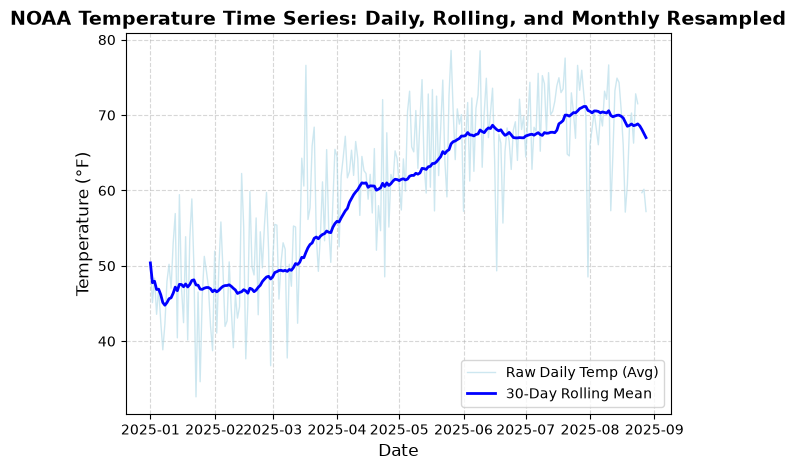

In [25]:
# Plot raw daily data with high transparency
plt.plot(daily_full.index, daily_full, label='Raw Daily Temp (Avg)', color='lightblue', alpha=0.6, linewidth=1)

# Plot smoothed 30-day rolling trend
plt.plot(rolling_30d.index, rolling_30d, label='30-Day Rolling Mean', color='blue', linewidth=2)

# Plot monthly resampled summary points
# Styling labels, title, and grid
plt.title('NOAA Temperature Time Series: Daily, Rolling, and Monthly Resampled', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Temperature (°F)', fontsize=12)
plt.legend(loc='best')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

# Display the plot
plt.show()